# 08 · Segmentasi Skala & Opportunity Score
### BNI Ecosystem & Growth Intelligence — Kelompok 8 · ODP BNI Data Analytics Batch 2

| # | Notebook | Isi |
|---|---|---|
| 06 | Model Evaluation | champion risiko XGBoost (angka resmi) |
| 07 | Post-evaluation | analisis kesalahan, audit label, aturan anomali v2 (shadow) |
| **08** | **Segmentasi & Opportunity Score** | **notebook ini — 3 segmen skala, skor peluang per segmen, nilai ekonomi (Rp), validasi ke adopsi Jul–Sep 2026** |

## Pertanyaan bisnis
*Nasabah mana yang sebaiknya didatangi RM bulan depan, untuk produk apa, dan berapa nilainya?*
Perusahaan kecil dan besar tidak dibandingkan langsung, karena dalam rupiah perusahaan kecil selalu kalah.
Jadi perusahaan dikelompokkan dulu menurut **skala**, lalu diranking **di dalam segmennya** (RM korporasi ≠ RM UKM).

## Aturan main (anti-kebocoran)
1. **Segmentasi** hanya memakai 7 fitur skala. Tidak ada fitur atau label risiko. K-means di-fit pada perusahaan `train` + `unlabeled`; `valid`/`test` cukup di-*predict*.
2. **Semua skor dihitung dari data ≤ bulan acuan.** Skor resmi memakai acuan **Jun 2026**.
3. **Pemilihan metode** (celah produk, kalibrasi konversi) memakai data **sebelum cutoff** saja:
   - **backtest:** skor per Des 2025 → produk yang dibuka Jan–Jun 2026;
   - **log aksi RM** Jan–Jun 2026.
4. **`outcome_product_adoption` (Jul–Sep 2026) dibuka sekali di bagian H**, hanya untuk validasi; disiplinnya sama dengan test di NB06.
5. **Nilai ekonomi (EV, Rp)** hanya informasi pendamping, **bukan dasar ranking**. Semua asumsinya ada di `assumptions_opportunity.csv`.

**Daftar isi:** A. Setup · B. Data & fitur skala · C. Segmentasi · D. Risiko per segmen · E. Komponen peluang & backtest · F. Kalibrasi konversi · G. Skor Jun 2026 + EV · H. Validasi Jul–Sep · I. Sensitivitas · J. Simpan & ringkasan · Daftar pustaka

## A. Setup

In [20]:
import json, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import joblib
from threadpoolctl import threadpool_limits
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, f1_score, log_loss,
                             normalized_mutual_info_score, recall_score, roc_auc_score, silhouette_score)
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90)
threadpool_limits(1)
SEED = 2026; T0 = time.time(); RNG = np.random.default_rng(SEED)

# ---- konfigurasi ----
REF_SCORE, REF_BACKTEST, REF_TRAIN = '2026-06', '2025-12', '2025-06'   # bulan acuan: skor resmi, backtest, latih model transisi
K_RANGE = range(2, 7); N_BOOT = 20; JACCARD_MIN = 0.85                # pemilihan k (Hennig 2007)
TOP_N = 50                                                            # daftar prioritas per segmen
WHY_NOW_MONTHS = 3; WHY_NOW_BONUS = 0.05; USE_ANOMALY_V2 = True       # alarm Apr–Jun 2026; v2 = rekomendasi NB07
MEDIUM_CREDIT_FACTOR = 0.5                                            # risiko Medium → peluang kredit × 0,5; High → kredit ditunda
N_BOOT_EV = 200
PRODUCT_NAMES = {}            # isi bila ada katalog, mis. {'P01': 'Giro', 'P06': 'Kredit Modal Kerja', ...}; kosong → pakai kode
# asumsi EV (ilustratif, horizon 12 bln; PD & LGD sama dengan NB06) — sepakati tim sebelum dikutip
ASSUMPTIONS = {
    'margin_kredit': 0.030,               # margin bersih tahunan atas plafon
    'margin_non_kredit': 0.010,           # fee/spread tahunan atas nilai deal dana/transaksi
    'biaya_aksi_Rp_juta': {'S1 Kecil': 0.5, 'S2 Menengah': 2.0, 'S3 Besar': 5.0},   # digital/telepon < RM komersial < RM korporasi
    'PD': {'Low': 0.01, 'Medium': 0.05, 'High': 0.20}, 'LGD': 0.45,
    'horizon_tahun': 1,                   # rencana §8b.5b: 12 bulan; uji sensitivitas memakai 3 tahun (nilai relasi)
}

In [21]:
def find_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / 'pyproject.toml').exists(): return p
    raise FileNotFoundError('pyproject.toml tidak ditemukan — jalankan notebook dari dalam folder proyek')
PROJECT_ROOT = find_root()
SRC, PROC, RAW = PROJECT_ROOT / 'src', PROJECT_ROOT / 'data' / 'processed', PROJECT_ROOT / 'data' / 'raw'
OUT = PROJECT_ROOT / 'outputs' / '08_segmentation'; FIG = OUT / 'figures'
M08 = PROJECT_ROOT / 'models' / '08_segmentation'; SCORES = PROJECT_ROOT / 'outputs' / 'scores'
REQUIRED = [SRC / 'opportunity.py', SCORES / 'risk_scores.csv', PROC / 'split.csv', PROC / 'features_anomaly_panel.csv.gz'] + \
           [RAW / f'{t}.csv' for t in ('companies', 'financials', 'relationships', 'product_holdings', 'rm_action_log', 'outcome_product_adoption')]
missing = [str(p.relative_to(PROJECT_ROOT)) for p in REQUIRED if not p.exists()]
if missing: raise FileNotFoundError('Berkas belum ada: ' + ', '.join(missing))
for d in (OUT, FIG, M08): d.mkdir(parents=True, exist_ok=True)
if str(SRC) not in sys.path: sys.path.insert(0, str(SRC))
import opportunity as OP

C = dict(s1='#2a78d6', s2='#eb6834', s3='#1baf7a', s4='#eda100', s5='#e87ba4', s6='#008300', s7='#6250d6', s8='#e34948',
         ink='#0b0b0b', ink2='#52514e', muted='#898781', grid='#e1e0d9', axis='#c3c2b7', surface='#fcfcfb')
SEG_COL = {'S1 Kecil': C['s1'], 'S2 Menengah': C['s2'], 'S3 Besar': C['s3']}
mpl.rcParams.update({'figure.facecolor': C['surface'], 'axes.facecolor': C['surface'], 'axes.edgecolor': C['axis'], 'axes.linewidth': .8,
                     'axes.grid': True, 'grid.color': C['grid'], 'grid.linewidth': .6, 'axes.axisbelow': True, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                     'axes.labelcolor': C['ink2'], 'axes.labelsize': 9, 'xtick.color': C['muted'], 'ytick.color': C['muted'],
                     'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.frameon': False, 'legend.fontsize': 8, 'lines.linewidth': 2,
                     'figure.dpi': 110, 'text.color': C['ink']})
def save_fig(fig, name): fig.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
def auc(y, s):
    y = np.asarray(y); return roc_auc_score(y, s) if 0 < y.mean() < 1 else np.nan
def month_end(ym): return str(pd.Period(ym, 'M').end_time.date())
def prev_months(ym, k): return str(pd.Period(ym, 'M') - k)

## B. Data & fitur skala
Tujuh fitur skala, tersedia untuk **semua** 2.000 perusahaan, termasuk prospect:
- karyawan;
- omzet, aset, ekuitas FY2025 (164 perusahaan tanpa laporan diimputasi dari karyawan; korelasi omzet–karyawan ±0,94);
- nilai transaksi relasi aktif, jumlah mitra, derajat graf.

Volume transaksi BNI **tidak** dipakai, karena prospect hanya terlihat sebagian. Fitur risiko dan industri juga tidak dipakai.

In [22]:
co = pd.read_csv(RAW / 'companies.csv').set_index('company_id')
fin = pd.read_csv(RAW / 'financials.csv'); rel = pd.read_csv(RAW / 'relationships.csv')
hold = pd.read_csv(RAW / 'product_holdings.csv'); act_log = pd.read_csv(RAW / 'rm_action_log.csv')
panel = pd.read_csv(PROC / 'features_anomaly_panel.csv.gz')
split = pd.read_csv(PROC / 'split.csv').set_index('company_id').split.reindex(co.index)
risk = pd.read_csv(SCORES / 'risk_scores.csv').set_index('company_id').reindex(co.index)

PRODUCTS = sorted(hold.product_id.unique())
CREDIT = sorted(hold.loc[hold.utilization.notna(), 'product_id'].unique())         # produk berutilisasi = kredit
UNIVERSAL = [p for p in PRODUCTS if hold[hold.product_id == p].company_id.nunique() >= 0.95 * hold.company_id.nunique()]
CAND = [p for p in PRODUCTS if p not in UNIVERSAL]                                  # produk yang bisa ditawarkan
pname = lambda p: PRODUCT_NAMES.get(p, p)
CLIENTS = co.index[co.customer_type != 'Prospect']; PROSPECTS = co.index[co.customer_type == 'Prospect']
FIT = co.index[split.isin(['train', 'unlabeled'])]

X_scale = OP.build_scale_features(co.reset_index(), fin, rel, fiscal_year=2025, ref_date=month_end(REF_SCORE))
print(f'{len(co)} perusahaan ({len(CLIENTS)} nasabah, {len(PROSPECTS)} prospect) · fit segmentasi pada {len(FIT)} perusahaan train+unlabeled')
print(f'produk: {PRODUCTS} · kredit (berutilisasi): {CREDIT} · dimiliki hampir semua nasabah (tidak ditawarkan): {UNIVERSAL}')
print(f'tanpa laporan FY2025: {X_scale.log_rev.isna().sum()} → diimputasi dari log karyawan')
display(X_scale.describe().T.round(2))

2000 perusahaan (1400 nasabah, 600 prospect) · fit segmentasi pada 1600 perusahaan train+unlabeled
produk: ['P01', 'P02', 'P03', 'P04', 'P05', 'P06', 'P07', 'P08'] · kredit (berutilisasi): ['P06', 'P07'] · dimiliki hampir semua nasabah (tidak ditawarkan): ['P01']
tanpa laporan FY2025: 164 → diimputasi dari log karyawan


,count,mean,std,min,25%,50%,75%,max
log_emp,2000.0,4.42,1.00,1.61,3.69,4.33,5.09,7.83
log_rev,1836.0,3.31,1.21,0.07,2.37,3.23,4.08,6.89
log_assets,1836.0,3.28,1.33,-0.69,2.27,3.19,4.10,7.48
log_equity,1836.0,2.42,1.32,-0.99,1.45,2.31,3.29,6.72
log_rel_value,2000.0,10.17,1.24,7.19,9.22,10.09,10.97,13.84
log_partners,2000.0,2.17,0.27,1.10,1.95,2.20,2.40,2.71
log_degree,2000.0,2.54,0.53,1.39,2.20,2.48,2.71,4.98


## C. Segmentasi (K-means, k = 2…6)
Pemilihan k dinilai dari **empat sudut**:
1. **internal:** silhouette, Davies–Bouldin, Calinski–Harabasz;
2. **stabilitas:** ARI bootstrap dan **Jaccard per segmen** (Hennig, 2007; patokan ≥ 0,85), 20 replikasi;
3. **validitas eksternal:** NMI dengan `size_class_reference` (hanya pembanding, tidak dipakai sebagai fitur);
4. **validitas bisnis:** beda konversi aksi RM (Deepening, Jan–Jun 2026; Cramér's V).

**Aturan pemilihan (ditulis sebelum dijalankan):**
- kandidat = k yang semua segmennya stabil (Jaccard minimum ≥ 0,85);
- di antara kandidat, pilih **Cramér's V konversi RM tertinggi**;
- bila selisih < 0,01, pilih NMI lebih tinggi; bila masih seri, pilih k lebih kecil.

In [23]:
def cramers_v(a, b):
    t = pd.crosstab(a, b); chi2, p, *_ = chi2_contingency(t); n = t.values.sum()
    return np.sqrt(chi2 / (n * (min(t.shape) - 1))), p

deep = act_log[(act_log.track == 'Deepening') & act_log.party_id.isin(CLIENTS)].copy()
Xfit = X_scale.loc[FIT]
rows = []
for k in K_RANGE:
    sg = OP.Segmenter(k=k, random_state=SEED).fit(Xfit)
    Zf = sg.transform(Xfit); lab_f = sg.predict(Xfit); lab_all = pd.Series(sg.predict(X_scale), index=co.index)
    aris, jac = [], np.zeros((N_BOOT, k))
    for b in range(N_BOOT):
        idx = RNG.choice(len(FIT), len(FIT), replace=True)
        sb = OP.Segmenter(k=k, random_state=SEED + b + 1, n_init=10).fit(Xfit.iloc[idx])
        lb = sb.predict(Xfit); aris.append(adjusted_rand_score(lab_f, lb))
        for c in range(k):
            A = lab_f == c
            jac[b, c] = max((A & (lb == d)).sum() / max((A | (lb == d)).sum(), 1) for d in range(k))
    v, p = cramers_v(deep.party_id.map(lab_all), deep.converted)
    rows.append(dict(k=k, silhouette=silhouette_score(Zf, lab_f), davies_bouldin=davies_bouldin_score(Zf, lab_f),
                     calinski_harabasz=calinski_harabasz_score(Zf, lab_f), ARI_bootstrap=np.mean(aris),
                     jaccard_min=jac.mean(0).min(), NMI_ukuran=normalized_mutual_info_score(co.size_class_reference, lab_all),
                     cramers_v_konversi_RM=v, p_konversi=p))
KSEL = pd.DataFrame(rows).set_index('k')
cand = KSEL[KSEL.jaccard_min >= JACCARD_MIN]
if len(cand) == 0:
    K_BEST = int(KSEL.jaccard_min.idxmax()); print('⚠ tidak ada k yang stabil; dipakai k dengan Jaccard tertinggi')
else:
    top = cand[cand.cramers_v_konversi_RM >= cand.cramers_v_konversi_RM.max() - 0.01]
    top = top[top.NMI_ukuran >= top.NMI_ukuran.max() - 1e-9]
    K_BEST = int(top.index.min())
KSEL['dipilih'] = KSEL.index == K_BEST; KSEL.to_csv(OUT / 'C_k_selection.csv')
display(KSEL.round(3))
print(f'→ k terpilih = {K_BEST}')

,silhouette,davies_bouldin,calinski_harabasz,ARI_bootstrap,jaccard_min,NMI_ukuran,cramers_v_konversi_RM,p_konversi,dipilih
k,,,,,,,,,
2,0.415,0.950,1465.696,0.893,0.923,0.393,0.083,0.001,False
3,0.341,1.020,1387.075,0.935,0.951,0.565,0.114,0.000,True
4,0.305,1.071,1192.275,0.840,0.827,0.495,0.108,0.001,False
5,0.276,1.031,1108.503,0.610,0.600,0.414,0.111,0.001,False
6,0.267,1.173,1053.806,0.615,0.600,0.408,0.104,0.006,False


→ k terpilih = 3


In [24]:
SEG = OP.Segmenter(k=K_BEST, random_state=SEED).fit(Xfit)
seg_lab = pd.Series(SEG.predict(X_scale), index=co.index)
seg = pd.Series(SEG.names(seg_lab.values), index=co.index)
seg_conf = pd.Series(SEG.confidence(X_scale), index=co.index)
SEGS = sorted(seg.unique(), key=lambda s: s.split()[0])
rev_bn = np.exp(SEG._impute(X_scale).log_rev)

n_prod_now = OP.holdings_at(hold, REF_SCORE, CLIENTS, PRODUCTS).sum(axis=1)
deep['seg'] = deep.party_id.map(seg)
PROF = pd.DataFrame({
    'n': seg.value_counts(), 'nasabah': seg[CLIENTS].value_counts(), 'prospect': seg[PROSPECTS].value_counts(),
    'median_omzet_Rp_M': rev_bn.groupby(seg).median(), 'median_karyawan': co.employees.groupby(seg).median(),
    'konversi_aksi_RM': deep.groupby('seg').converted.mean(), 'n_aksi_RM': deep.groupby('seg').size(),
    'rata2_produk_aktif': n_prod_now.groupby(seg[CLIENTS]).mean(), 'keyakinan_segmen_median': seg_conf.groupby(seg).median()}).loc[SEGS]
PROF.to_csv(OUT / 'C_segment_profile.csv'); display(PROF.round(3))
XT = pd.crosstab(seg, co.size_class_reference).loc[SEGS, ['Kecil', 'Menengah', 'Besar']]
agree = sum(XT.loc[s, s.split()[1]] for s in SEGS if s.split()[1] in XT.columns) / len(co) if K_BEST == 3 else np.nan
display(XT); print(f'selaras dengan size_class_reference: {agree:.0%}' if K_BEST == 3 else '')
v_seg, _ = cramers_v(deep.seg, deep.converted); v_ref, _ = cramers_v(deep.party_id.map(co.size_class_reference), deep.converted)
print(f"Cramér's V konversi RM: segmen {v_seg:.3f} vs kolom ukuran bank {v_ref:.3f}")

,n,nasabah,prospect,median_omzet_Rp_M,median_karyawan,konversi_aksi_RM,n_aksi_RM,rata2_produk_aktif,keyakinan_segmen_median
S1 Kecil,796,429,367,8.311,34.5,0.126,476,2.823,0.530
S2 Menengah,863,659,204,34.710,109.0,0.150,692,3.171,0.475
S3 Besar,341,312,29,172.730,344.0,0.238,332,3.692,0.540


size_class_reference,Kecil,Menengah,Besar
row_0,,,
S1 Kecil,687,109,0
S2 Menengah,123,713,27
S3 Besar,0,32,309


selaras dengan size_class_reference: 85%
Cramér's V konversi RM: segmen 0.114 vs kolom ukuran bank 0.113


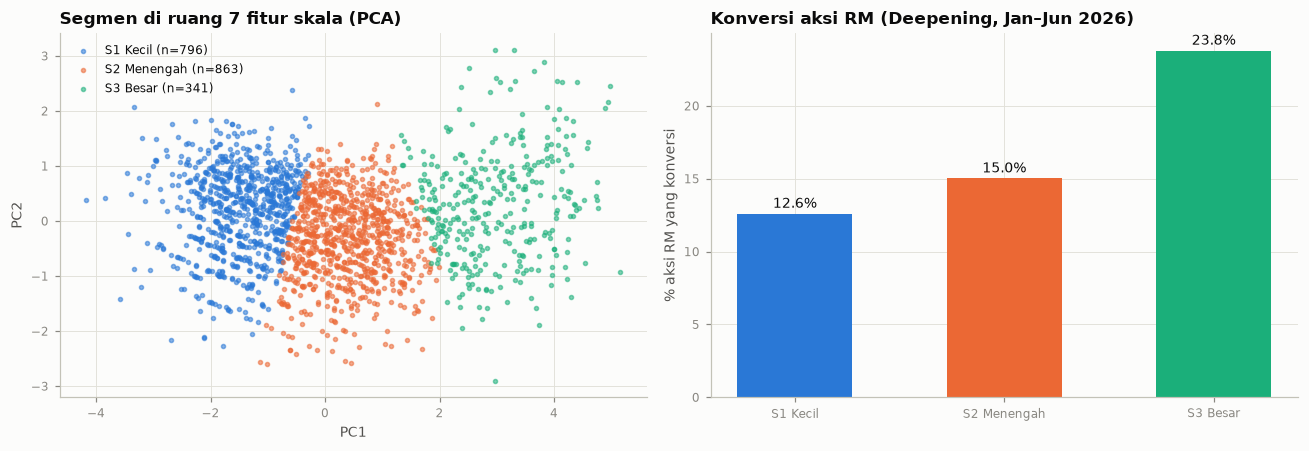

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
Z2 = PCA(2, random_state=SEED).fit(SEG.transform(Xfit)).transform(SEG.transform(X_scale))
for s in SEGS:
    m = (seg == s).values; ax[0].scatter(Z2[m, 0], Z2[m, 1], s=7, alpha=.55, color=SEG_COL.get(s, C['s4']), label=f'{s} (n={m.sum()})')
ax[0].set_title('Segmen di ruang 7 fitur skala (PCA)'); ax[0].set_xlabel('PC1'); ax[0].set_ylabel('PC2'); ax[0].legend()
x = np.arange(len(SEGS)); ax[1].bar(x, PROF.konversi_aksi_RM.values * 100, color=[SEG_COL.get(s) for s in SEGS], width=.55)
for i, v in enumerate(PROF.konversi_aksi_RM.values * 100): ax[1].text(i, v + .4, f'{v:.1f}%', ha='center', fontsize=9)
ax[1].set_xticks(x); ax[1].set_xticklabels(SEGS); ax[1].set_ylabel('% aksi RM yang konversi'); ax[1].set_title('Konversi aksi RM (Deepening, Jan–Jun 2026)')
plt.tight_layout(); save_fig(fig, 'C_segments'); plt.show()

## D. Model risiko per segmen (cek, bukan model baru)
Sesuai rencana §5.5b, model risiko tetap **satu model global**. Di sini hanya dicek apakah kinerjanya merata di tiap segmen.
Data: nasabah kredit di **test** (dari `risk_scores.csv` NB06), label rating dari `features_risk`.

In [26]:
fr = pd.read_csv(PROC / 'features_risk.csv.gz').set_index('company_id')
te = risk[(risk.pred_source == 'test')].copy() if 'pred_source' in risk else risk.iloc[0:0]
te['y'] = fr.risk_class.reindex(te.index); te = te[te.y.notna()]; te['seg'] = seg.reindex(te.index)
rows = []
for s, g in te.groupby('seg'):
    cov = np.mean([y in str(cs) for y, cs in zip(g.y, g.conformal_set)]) if 'conformal_set' in g else np.nan
    rows.append(dict(segmen=s, n=len(g), n_High=(g.y == 'High').sum(), macro_F1=f1_score(g.y, g.pred_class, average='macro'),
                     recall_High=recall_score(g.y == 'High', g.pred_class == 'High') if (g.y == 'High').any() else np.nan,
                     cakupan_conformal=cov, pct_otomatis=(g.decision == 'Otomatis').mean() if 'decision' in g else np.nan))
RISK_SEG = pd.DataFrame(rows).set_index('segmen'); RISK_SEG.to_csv(OUT / 'D_risk_by_segment_test.csv'); display(RISK_SEG.round(3))
print('Catatan: n High per segmen kecil → rentang lebar; dipakai untuk memantau, bukan untuk ambang per segmen.')

,n,n_High,macro_F1,recall_High,cakupan_conformal,pct_otomatis
segmen,,,,,,
S1 Kecil,58,11,0.709,0.909,0.966,0.345
S2 Menengah,101,13,0.603,0.923,0.881,0.485
S3 Besar,41,4,0.582,0.750,0.927,0.488


Catatan: n High per segmen kecil → rentang lebar; dipakai untuk memantau, bukan untuk ambang per segmen.


## E. Komponen peluang & backtest metode "celah produk"
**Komponen** (persentil di dalam segmen):

| Komponen | Isi | Data |
|---|---|---|
| Dompet belum digarap | (1 − capture) × omzet (Rp) | panel arus kas + laporan |
| Ekosistem | mitra non-BNI + nilai relasi aktif | relasi |
| Kebutuhan modal | pertumbuhan inflow 3v6 + CUSUM naik | panel |
| Celah produk | peluang produk yang belum dimiliki (lihat di bawah); kredit ditunda bila risiko High, × 0,5 bila Medium | kepemilikan |
| Erosi wallet | penurunan capture 6 bulan | panel |

**Celah produk: tiga kandidat, dipilih lewat backtest pra-cutoff** (skor per Des 2025 → produk yang dibuka Jan–Jun 2026):
- **champion (rencana §8b.5): peer rate.** Porsi peer (segmen × industri) yang sudah memegang produk itu. Sederhana dan mudah dijelaskan ke RM.
- **challenger 1, look-alike:** regresi logistik P(memegang produk | profil, produk lain) pada bulan acuan.
- **challenger 2, transisi:** regresi logistik P(membuka produk dalam 6 bulan | profil, produk lain), dilatih pada transisi Jul–Des 2025.

**Aturan:** challenger menggantikan peer rate **hanya bila** interval bootstrap 95% (per perusahaan) dari ΔAUC tingkat produk seluruhnya > 0.

*Batasan data:* snapshot kepemilikan hanya mencatat produk yang **masih aktif** di Jun 2026. Produk yang sudah ditutup sebelum itu tidak terlihat, sehingga kepemilikan masa lalu sedikit di-*under*-estimasi.

In [27]:
def profile_at(ref, ids):
    """Fitur profil & perilaku pada bulan acuan (hanya data ≤ ref)."""
    fy = int(ref[:4]) - 1                                               # laporan tahun lalu (terbit di tahun berjalan)
    f = fin[fin.fiscal_year == fy].set_index('company_id').reindex(ids)
    onb = pd.PeriodIndex(pd.to_datetime(co.onboarding_date.reindex(ids)), freq='M')
    F = pd.DataFrame(index=ids)
    for s in SEGS: F['seg_' + s.split()[0]] = (seg.reindex(ids) == s).astype(int)
    F['log_emp'] = np.log(co.employees.reindex(ids)); F['age'] = int(ref[:4]) - co.establishment_year.reindex(ids)
    F['tenure'] = [(pd.Period(ref, 'M') - o).n / 12 if pd.notna(o) else np.nan for o in onb]
    F['listed'] = co.is_listed.reindex(ids).astype(int); F['impor'] = co.has_import_activity.reindex(ids).astype(int)
    F['payroll_bank_lain'] = (co.payroll_bank.reindex(ids) != 'BNI').astype(int); F['anchor'] = co.is_anchor_candidate.reindex(ids).astype(int)
    F['log_rev'] = np.log(f.revenue_idr_bn.clip(lower=1e-3))
    F['log_der'] = np.log((f.total_debt_idr_bn / f.total_equity_idr_bn.clip(lower=1e-3)).clip(lower=1e-3))
    F['log_cr'] = np.log((f.current_assets_idr_bn / f.current_liabilities_idr_bn.clip(lower=1e-3)).clip(lower=1e-3))
    F['npm'] = f.net_profit_idr_bn / f.revenue_idr_bn.clip(lower=1e-3)
    p = panel[panel.ym == ref].set_index('company_id').reindex(ids)
    for c in ['chg_3v6', 'capture_t', 'capture_chg_6m', 'out_in_3m', 'n_active_cp_3m', 'cusum_up']: F[c] = p[c]
    for ind in sorted(co.industry.unique()): F['ind_' + ind[:14]] = (co.industry.reindex(ids) == ind).astype(int)
    return F

def onboarded_by(ref, ids):
    o = pd.to_datetime(co.onboarding_date.reindex(ids)).dt.strftime('%Y-%m'); return ids[(o <= ref).values]

def state_at(ref):
    ids = onboarded_by(ref, CLIENTS)
    H = OP.holdings_at(hold, ref, ids, PRODUCTS)
    F = profile_at(ref, ids)
    for q in PRODUCTS: F['h_' + q] = H[q]
    F['n_prod'] = H.sum(axis=1)
    return ids, H, F

def opened_between(a, b):
    o = hold[(hold.open_month > a) & (hold.open_month <= b)]; return set(zip(o.company_id, o.product_id))

def long_rows(ids, H, F, opened=None):
    out = []
    for q in CAND:
        m = (H[q] == 0).values; X = F.loc[ids[m]].copy(); X['prod'] = q
        if opened is not None: X['y'] = [int((c, q) in opened) for c in X.index]
        out.append(X)
    return pd.concat(out)

LR = lambda C_=0.3: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=C_, max_iter=3000))
def feat_cols(F, q): return [c for c in F.columns if c not in ('y', 'prod', 'h_' + q) and F[c].notna().any()]

def need_lookalike(ids, H, F):
    """P(memegang q | profil, produk lain), di-fit pada bulan acuan yang sama (lintas perusahaan)."""
    N = pd.DataFrame(0.0, index=ids, columns=CAND)
    for q in CAND:
        cols = feat_cols(F, q); m = LR().fit(F[cols], H[q]); N[q] = m.predict_proba(F[cols])[:, 1]
    return N.where(H[CAND] == 0, 0.0), None

def fit_transition(train_long):
    models = {}
    for q in CAND:
        a = train_long[train_long['prod'] == q]; cols = feat_cols(a, q)
        if a.y.sum() >= 5: models[q] = (cols, LR(0.1).fit(a[cols], a.y))
    return models

def need_transition(ids, H, F, models):
    N = pd.DataFrame(0.0, index=ids, columns=CAND)
    for q, (cols, m) in models.items(): N[q] = m.predict_proba(F.reindex(columns=cols))[:, 1]
    return N.where(H[CAND] == 0, 0.0)

def need_peer(ids, H):
    R = OP.peer_rate(H[CAND], seg.reindex(ids).astype(str) + '|' + co.industry.reindex(ids).astype(str), fallback=seg.reindex(ids))
    return R.where(H[CAND] == 0, 0.0)

# backtest: acuan Des 2025 → dibuka Jan–Jun 2026
ids_bt, H_bt, F_bt = state_at(REF_BACKTEST)
ids_tr, H_tr, F_tr = state_at(REF_TRAIN)
TR_LONG = long_rows(ids_tr, H_tr, F_tr, opened_between(REF_TRAIN, REF_BACKTEST))
BT_OPEN = opened_between(REF_BACKTEST, REF_SCORE)
NEEDS_BT = {'peer rate (champion)': need_peer(ids_bt, H_bt), 'look-alike': need_lookalike(ids_bt, H_bt, F_bt)[0],
            'transisi': need_transition(ids_bt, H_bt, F_bt, fit_transition(TR_LONG))}
BT = long_rows(ids_bt, H_bt, F_bt, BT_OPEN)[['prod', 'y']]
for k_, N in NEEDS_BT.items(): BT[k_] = [N.at[c, q] for c, q in zip(BT.index, BT['prod'])]
BT['seg'] = seg.reindex(BT.index).values
print(f'backtest: {len(BT):,} pasangan nasabah×produk belum dimiliki per Des 2025; dibuka Jan–Jun 2026: {BT.y.sum()} ({BT.y.mean():.1%})')
print(f'data latih transisi (Jun→Des 2025): {len(TR_LONG):,} baris, dibuka {TR_LONG.y.sum()}')

def boot_delta(df, a, b, B=300):
    """Bootstrap per perusahaan (cluster): bobot baris = berapa kali perusahaannya terambil."""
    codes, uniq = pd.factorize(df.index); rng = np.random.default_rng(SEED); d = []
    y, sa, sb = df.y.values, df[a].values, df[b].values
    for _ in range(B):
        w = np.bincount(rng.integers(0, len(uniq), len(uniq)), minlength=len(uniq))[codes]
        d.append(roc_auc_score(y, sb, sample_weight=w) - roc_auc_score(y, sa, sample_weight=w))
    return np.percentile(d, [2.5, 97.5])

rows = []
for k_ in NEEDS_BT:
    r = dict(metode=k_, AUC_produk=auc(BT.y, BT[k_]))
    for s in SEGS: r[f'AUC_{s}'] = auc(BT.y[BT.seg == s], BT[k_][BT.seg == s])
    for q in CAND: r[f'AUC_{pname(q)}'] = auc(BT.y[BT['prod'] == q], BT[k_][BT['prod'] == q])
    if k_ != 'peer rate (champion)':
        lo, hi = boot_delta(BT, 'peer rate (champion)', k_); r['dAUC_vs_peer_95%'] = f'{lo:+.3f} … {hi:+.3f}'; r['menang'] = lo > 0
    rows.append(r)
NEED_SEL = pd.DataFrame(rows).set_index('metode'); NEED_SEL.to_csv(OUT / 'E_need_method_backtest.csv'); display(NEED_SEL.round(3))
winners = NEED_SEL[NEED_SEL.get('menang', False) == True]
NEED_METHOD = winners.AUC_produk.idxmax() if len(winners) else 'peer rate (champion)'
print(f'→ metode celah produk: {NEED_METHOD}')

backtest: 6,785 pasangan nasabah×produk belum dimiliki per Des 2025; dibuka Jan–Jun 2026: 234 (3.4%)
data latih transisi (Jun→Des 2025): 6,817 baris, dibuka 367


,AUC_produk,AUC_S1 Kecil,AUC_S2 Menengah,AUC_S3 Besar,AUC_P02,AUC_P03,AUC_P04,AUC_P05,AUC_P06,AUC_P07,AUC_P08,dAUC_vs_peer_95%,menang
metode,,,,,,,,,,,,,
peer rate (champion),0.605,0.620,0.586,0.529,0.538,0.638,0.626,0.674,0.581,0.459,0.620,NaN,NaN
look-alike,0.598,0.694,0.608,0.481,0.538,0.613,0.501,0.572,0.614,0.536,0.805,-0.041 … +0.038,False
transisi,0.588,0.662,0.598,0.480,0.534,0.571,0.591,0.670,0.490,0.384,0.833,-0.057 … +0.029,False


→ metode celah produk: peer rate (champion)


### E2. Skor gabungan di backtest: bobot bisnis vs celah produk saja
Laporan saja, bukan pemilihan. Bobot per segmen sudah diputuskan di rencana §8b.5 sebagai **kebijakan bisnis**:
segmen besar menekankan dompet & ekosistem, segmen kecil menekankan celah produk.
Backtest menunjukkan harga kebijakan itu, yaitu berapa presisi adopsi yang dikorbankan demi nilai dan retensi.

In [28]:
def why_now_flags(ref):
    f2 = SCORES / 'anomaly_alerts_v2_shadow.csv'; f1 = SCORES / 'anomaly_alerts.csv'
    if USE_ANOMALY_V2 and f2.exists(): al = pd.read_csv(f2); src = 'v2 (NB07, shadow)'
    elif f1.exists():
        al = pd.read_csv(f1); al = al[al.champion_or_shadow == 'champion'] if 'champion_or_shadow' in al else al; src = 'v1 (NB04/NB06)'
    else: return pd.Series(0, index=co.index), pd.Series(0, index=co.index), pd.Series('', index=co.index), 'tidak ada'
    al = al[(al.ym > prev_months(ref, WHY_NOW_MONTHS)) & (al.ym <= ref)]
    up = al[al.event_type.isin(OP.WHY_NOW_UP)]; cau = al[al.event_type.isin(OP.WHY_NOW_CAUTION)]
    txt = al.groupby('company_id').event_type.agg(lambda s: ', '.join(sorted(set(s))))
    return (co.index.isin(up.company_id).astype(int), co.index.isin(cau.company_id).astype(int), txt.reindex(co.index).fillna(''), src)

def components_at(ref, ids, H, need, risk_class=None):
    pan = panel[panel.ym == ref].set_index('company_id')
    fy = int(ref[:4]) - 1
    rv = fin[fin.fiscal_year == fy].set_index('company_id').revenue_idr_bn.reindex(ids)
    rv = rv.fillna(pd.Series(np.exp(SEG._impute(X_scale).log_rev), index=co.index).reindex(ids))
    Cm, _ = OP.build_components(ids, seg.reindex(ids).values, co.industry.reindex(ids).values, H[CAND], pan, rv.values, rel,
                                month_end(ref), CREDIT, risk_class=None)
    N = need.copy()
    if risk_class is not None:
        rc = pd.Series(risk_class, index=ids); cp = [p for p in CREDIT if p in N]
        N.loc[rc == 'High', cp] = 0.0; N.loc[rc == 'Medium', cp] *= MEDIUM_CREDIT_FACTOR
    Cm['celah_produk'] = N.max(axis=1)
    return Cm, N

NEED_BT = NEEDS_BT[NEED_METHOD]
up_bt, _, _, _ = why_now_flags(REF_BACKTEST)
C_bt, _ = components_at(REF_BACKTEST, ids_bt, H_bt, NEED_BT)
S_bt, P_bt = OP.opportunity_score(C_bt, seg.reindex(ids_bt).values, why_now_up=pd.Series(up_bt, index=co.index).reindex(ids_bt).values, bonus=WHY_NOW_BONUS)
G = pd.DataFrame({'seg': seg.reindex(ids_bt), 'skor_gabungan': S_bt, 'celah_produk_saja': C_bt.celah_produk,
                  'omzet_saja': rev_bn.reindex(ids_bt)})
G['y'] = [int(any((c, q) in BT_OPEN for q in CAND)) for c in ids_bt]
rows = []
for s in SEGS:
    g = G[G.seg == s]
    for col in ['skor_gabungan', 'celah_produk_saja', 'omzet_saja']:
        rows.append(dict(segmen=s, ranking=col, n=len(g), dasar=g.y.mean(), presisi_top=g.nlargest(TOP_N, col).y.mean(), AUC=auc(g.y, g[col])))
BT_COMP = pd.DataFrame(rows); BT_COMP['lift'] = BT_COMP.presisi_top / BT_COMP.dasar
BT_COMP.to_csv(OUT / 'E2_backtest_company_level.csv', index=False)
display(BT_COMP.pivot(index='segmen', columns='ranking', values=['presisi_top', 'lift']).round(2))

presisi_top                                       lift                         
ranking     celah_produk_saja omzet_saja skor_gabungan celah_produk_saja omzet_saja skor_gabungan
segmen                                                                                           
S1 Kecil                 0.16       0.14          0.22              1.18       1.03          1.62
S2 Menengah              0.22       0.16          0.28              1.50       1.09          1.90
S3 Besar                 0.32       0.10          0.22              1.52       0.47          1.04

## F. Kalibrasi peluang konversi dari log aksi RM (Jan–Jun 2026)
**Tujuan:** mengubah skor menjadi **P(konversi bila didatangi)** per nasabah × produk, sebagai bahan EV.

**Anti-kebocoran:** aksi RM terjadi Jan–Jun 2026, sedangkan produk yang berhasil dijual sudah tercatat di snapshot Jun 2026.
Karena itu skor yang dipakai adalah skor per **Des 2025**, sebelum aksi berlangsung.

- **Model:** regresi logistik `konversi ~ segmen + produk + skor gabungan + celah produk (produk yang ditawarkan)`.
- **Pembanding:** `segmen + produk` saja.
- **Evaluasi:** GroupKFold 5 per perusahaan.

**Aturan:** skor dipakai bila log-loss CV lebih rendah daripada pembanding. Bila tidak, P(konversi) = rata-rata segmen × produk.

*Batasan:* RM memilih sendiri siapa yang didatangi (bias seleksi), jadi P(konversi) berlaku untuk nasabah **yang mirip dengan yang biasa didatangi**.

In [29]:
deep_bt = deep[deep.party_id.isin(ids_bt) & deep.product_id.isin(CAND)].copy()
deep_bt['skor'] = deep_bt.party_id.map(S_bt); deep_bt['celah'] = [NEED_BT.at[c, q] for c, q in zip(deep_bt.party_id, deep_bt.product_id)]
def design(df, with_score):
    X = pd.get_dummies(df[['seg', 'product_id']].astype(str), dtype=float)
    if with_score: X['skor'] = df.skor.values; X['celah'] = df.celah.values
    return X
def cv_ll(with_score):
    P = np.zeros(len(deep_bt)); y = deep_bt.converted.values
    for tr, te_ in GroupKFold(5).split(deep_bt, y, deep_bt.party_id):
        Xa, Xb = design(deep_bt.iloc[tr], with_score), design(deep_bt.iloc[te_], with_score).reindex(columns=design(deep_bt.iloc[tr], with_score).columns, fill_value=0)
        P[te_] = LR(1.0).fit(Xa, y[tr]).predict_proba(Xb)[:, 1]
    return log_loss(y, P), auc(y, P), P
ll0, a0, _ = cv_ll(False); ll1, a1, P_cv = cv_ll(True)
USE_SCORE_IN_CONV = ll1 < ll0
CAL = pd.DataFrame({'model': ['segmen + produk', 'segmen + produk + skor + celah'], 'log_loss_CV': [ll0, ll1], 'AUC_CV': [a0, a1]})
CAL.to_csv(OUT / 'F_conversion_calibration.csv', index=False); display(CAL.round(4))
print(f'{len(deep_bt)} aksi Deepening ({deep_bt.converted.mean():.1%} konversi) · skor dipakai di P(konversi): {USE_SCORE_IN_CONV}')
CONV_MODEL = LR(1.0).fit(design(deep_bt, USE_SCORE_IN_CONV), deep_bt.converted)
CONV_COLS = list(design(deep_bt, USE_SCORE_IN_CONV).columns)
display(pd.Series(CONV_MODEL[-1].coef_[0], index=CONV_COLS).round(3).to_frame('koef (terstandar)').T)

,model,log_loss_CV,AUC_CV
0,segmen + produk,0.4306,0.6179
1,segmen + produk + skor + celah,0.4275,0.6350


1456 aksi Deepening (16.1% konversi) · skor dipakai di P(konversi): True


,seg_S1 Kecil,seg_S2 Menengah,seg_S3 Besar,product_id_P02,product_id_P03,product_id_P04,product_id_P05,product_id_P06,product_id_P07,product_id_P08,skor,celah
koef (terstandar),-0.079,-0.048,0.147,0.079,0.194,0.082,0.131,-0.116,-0.396,-0.057,0.122,0.318


## G. Skor resmi per Jun 2026 + nilai ekonomi
- **Penyesuaian risiko** (model NB06, `pred_class`): **High** → produk kredit **ditunda** sampai review analis (produk non-kredit tetap); **Medium** → peluang kredit × 0,5.
- **Why Now:** alarm ekspansi atau erosi wallet dalam 3 bulan terakhir → +0,05 pada skor dasar sebelum persentil akhir. Alarm distress, pembeli keluar, atau efek berantai → tanda **hati-hati** (tanpa bonus).
- **Produk yang disarankan:** 2 produk dengan P(konversi) tertinggi dari produk yang belum dimiliki dan boleh ditawarkan.
- **EV (Rp juta) per produk** = P(konversi) × ukuran deal × (margin − PD × LGD, khusus kredit) × horizon − biaya aksi. Horizon default 1 tahun (rencana); 3 tahun diuji di bagian I.
  - Ukuran deal = median deal yang berhasil di log aksi RM, per segmen × produk.
  - Rentangnya (p10–p90) dari bootstrap ukuran deal.

In [30]:
ids_s, H_s, F_s = state_at(REF_SCORE)
if NEED_METHOD == 'peer rate (champion)': NEED_RAW = need_peer(ids_s, H_s); NEED_MODEL = None
elif NEED_METHOD == 'look-alike': NEED_RAW = need_lookalike(ids_s, H_s, F_s)[0]; NEED_MODEL = None
else:
    full_long = pd.concat([TR_LONG, long_rows(ids_bt, H_bt, F_bt, BT_OPEN)]); NEED_MODEL = fit_transition(full_long)
    NEED_RAW = need_transition(ids_s, H_s, F_s, NEED_MODEL)
rc_s = risk.pred_class.reindex(ids_s).fillna('Low').values
up_s, cau_s, why_txt, WHY_SRC = why_now_flags(REF_SCORE)
up_s, cau_s = pd.Series(up_s, index=co.index), pd.Series(cau_s, index=co.index)
C_s, NEED_S = components_at(REF_SCORE, ids_s, H_s, NEED_RAW, risk_class=rc_s)
S_s, PCT_s = OP.opportunity_score(C_s, seg.reindex(ids_s).values, why_now_up=up_s.reindex(ids_s).values, bonus=WHY_NOW_BONUS)
print(f'{len(ids_s)} nasabah diskor · Why Now dari alarm {WHY_SRC}: naik {up_s[ids_s].sum()}, hati-hati {cau_s[ids_s].sum()}')

# P(konversi) per nasabah × produk yang boleh ditawarkan
PL = NEED_S.rename_axis('company_id').reset_index().melt(id_vars='company_id', var_name='product_id', value_name='celah')
held = H_s[CAND].rename_axis('company_id').reset_index().melt(id_vars='company_id', var_name='product_id', value_name='held')
PL = PL.merge(held, on=['company_id', 'product_id']); PL = PL[PL.held == 0].drop(columns='held').reset_index(drop=True)
PL['seg'] = PL.company_id.map(seg); PL['skor'] = PL.company_id.map(S_s)
PL['risk_class'] = PL.company_id.map(risk.pred_class).fillna('Low')
PL['ditunda_risiko'] = PL.product_id.isin(CREDIT) & (PL.risk_class == 'High')
Xp = design(PL, USE_SCORE_IN_CONV).reindex(columns=CONV_COLS, fill_value=0)
PL['p_konversi'] = CONV_MODEL.predict_proba(Xp)[:, 1]
PL.loc[PL.ditunda_risiko, 'p_konversi'] = 0.0
PL.loc[PL.product_id.isin(CREDIT) & (PL.risk_class == 'Medium'), 'p_konversi'] *= MEDIUM_CREDIT_FACTOR

# ukuran deal per segmen × produk (+ bootstrap)
won = deep[deep.converted == 1].copy()
def deal_table(df):
    t = df.groupby(['seg', 'product_id']).deal_value_idr_mn.agg(['median', 'size'])
    prod_med = df.groupby('product_id').deal_value_idr_mn.median(); allm = df.deal_value_idr_mn.median()
    out = {}
    for s in SEGS:
        for q in CAND:
            if (s, q) in t.index and t.loc[(s, q), 'size'] >= 5: out[(s, q)] = t.loc[(s, q), 'median']
            else: out[(s, q)] = prod_med.get(q, allm)
    return pd.Series(out)
DEAL = deal_table(won)
DEAL_B = pd.concat([deal_table(won.sample(len(won), replace=True, random_state=SEED + b)) for b in range(N_BOOT_EV)], axis=1)

pd_exp = (risk[['p_low', 'p_medium', 'p_high']].fillna({'p_low': 1, 'p_medium': 0, 'p_high': 0}) @
          np.array([ASSUMPTIONS['PD']['Low'], ASSUMPTIONS['PD']['Medium'], ASSUMPTIONS['PD']['High']]))
def ev_rows(PL, deal, A=ASSUMPTIONS):
    d = np.array([deal[(s, q)] for s, q in zip(PL.seg, PL.product_id)])
    cr = PL.product_id.isin(CREDIT).values
    margin = np.where(cr, A['margin_kredit'], A['margin_non_kredit'])
    loss = np.where(cr, pd_exp.reindex(PL.company_id).values * A['LGD'], 0.0)
    cost = PL.seg.map(A['biaya_aksi_Rp_juta']).values
    return PL.p_konversi.values * d * (margin - loss) * A['horizon_tahun'] - cost, d
PL['ev_Rp_juta'], PL['ukuran_deal_Rp_juta'] = ev_rows(PL, DEAL)
EVB = np.column_stack([ev_rows(PL, DEAL_B[b])[0] for b in DEAL_B.columns])
PL['ev_p10'], PL['ev_p90'] = np.percentile(EVB, 10, axis=1), np.percentile(EVB, 90, axis=1)
PL['roi'] = PL.ev_Rp_juta / PL.seg.map(ASSUMPTIONS['biaya_aksi_Rp_juta'])          # EV ÷ biaya aksi
PL['rank_produk'] = PL.groupby('company_id').p_konversi.rank(ascending=False, method='first')
PL['nama_produk'] = PL.product_id.map(pname)

1400 nasabah diskor · Why Now dari alarm v2 (NB07, shadow): naik 129, hati-hati 340


In [31]:
REASON = {'dompet_belum_digarap': 'dompet belum digarap besar', 'ekosistem': 'ekosistem/mitra luas',
          'kebutuhan_modal': 'arus kas tumbuh (butuh modal)', 'celah_produk': 'produk umum di peer belum dimiliki',
          'erosi_wallet': 'porsi wallet BNI turun (retensi)'}
top2 = PL[PL.rank_produk <= 2].sort_values(['company_id', 'rank_produk'])
rec = top2.groupby('company_id').nama_produk.agg(', '.join)
ev1 = PL[PL.rank_produk == 1].set_index('company_id')
OPP = pd.DataFrame(index=ids_s)
OPP['segment'] = seg.reindex(ids_s); OPP['segment_confidence'] = seg_conf.reindex(ids_s).round(3)
OPP['customer_type'] = co.customer_type.reindex(ids_s)
for k_ in OP.COMPONENTS: OPP['pct_' + k_] = PCT_s[k_].round(3)
OPP['opportunity_score'] = S_s.round(4)
OPP['rank_in_segment'] = OPP.groupby('segment').opportunity_score.rank(ascending=False, method='first').astype(int)
OPP['risk_class'] = risk.pred_class.reindex(ids_s); OPP['risk_adjustment'] = OPP.risk_class.map({'High': 'kredit ditunda (review analis)', 'Medium': f'kredit × {MEDIUM_CREDIT_FACTOR}'}).fillna('-')
OPP['why_now_up'] = up_s.reindex(ids_s); OPP['why_now_caution'] = cau_s.reindex(ids_s); OPP['why_now_events'] = why_txt.reindex(ids_s)
OPP['recommended_products'] = rec.reindex(ids_s).fillna('-')
OPP['reason'] = [' · '.join(REASON[k_] for k_ in PCT_s.loc[c].sort_values(ascending=False).index[:2]) for c in ids_s]
OPP['p_convert'] = ev1.p_konversi.reindex(ids_s).round(4)
OPP['ev_idr_mn'] = ev1.ev_Rp_juta.reindex(ids_s).round(2); OPP['ev_low'] = ev1.ev_p10.reindex(ids_s).round(2); OPP['ev_high'] = ev1.ev_p90.reindex(ids_s).round(2)
OPP['ev_top2_idr_mn'] = top2.groupby('company_id').ev_Rp_juta.sum().reindex(ids_s).round(2)
OPP['roi'] = ev1.roi.reindex(ids_s).round(2)
display(OPP.sort_values(['segment', 'rank_in_segment']).groupby('segment').head(3)[
    ['segment', 'rank_in_segment', 'opportunity_score', 'risk_class', 'why_now_events', 'recommended_products', 'reason', 'p_convert', 'ev_idr_mn']])

,segment,rank_in_segment,opportunity_score,risk_class,why_now_events,recommended_products,reason,p_convert,ev_idr_mn
company_id,,,,,,,,,
C1892,S1 Kecil,1,1.0000,Low,,"P03, P06",arus kas tumbuh (butuh modal) · produk umum di peer belum dimiliki,0.3202,0.20
C1983,S1 Kecil,2,0.9977,Low,,"P06, P03",arus kas tumbuh (butuh modal) · produk umum di peer belum dimiliki,0.2033,0.32
C1014,S1 Kecil,3,0.9953,Low,,"P06, P03",ekosistem/mitra luas · porsi wallet BNI turun (retensi),0.1894,0.26
C1770,S2 Menengah,1,1.0000,Low,expansion,"P03, P08",dompet belum digarap besar · porsi wallet BNI turun (retensi),0.2258,-1.01
C1211,S2 Menengah,2,0.9985,Medium,,"P02, P05",arus kas tumbuh (butuh modal) · porsi wallet BNI turun (retensi),0.2344,-0.86
C1085,S2 Menengah,3,0.9970,Low,expansion,"P03, P06",produk umum di peer belum dimiliki · arus kas tumbuh (butuh modal),0.3127,-0.63
C1061,S3 Besar,1,1.0000,Low,,"P02, P04",arus kas tumbuh (butuh modal) · dompet belum digarap besar,0.3495,2.06
C1195,S3 Besar,2,0.9968,Low,,"P03, P05",porsi wallet BNI turun (retensi) · dompet belum digarap besar,0.5023,3.16
C1355,S3 Besar,3,0.9936,Low,,"P02, P04",arus kas tumbuh (butuh modal) · ekosistem/mitra luas,0.3488,2.04


### G2. Prospect: skor akuisisi (deskriptif)
Log aksi RM tidak memuat satu pun konversi prospect pada Jan–Jun 2026, jadi tidak ada data untuk mengkalibrasi atau memvalidasi skor prospect.
Skor akuisisi dibuat **transparan** dan **ditandai belum tervalidasi**:
- persentil dalam segmen dari (skala + ekosistem + jumlah relasi dengan nasabah BNI, yaitu jalur perkenalan lewat rantai pasok);
- prospect yang di-flag High oleh model risiko diberi tanda "produk kredit ditunda".

In [32]:
actr = OP.active_relations(rel, month_end(REF_SCORE))
link_bni = pd.concat([actr[actr.target_id.isin(CLIENTS)].groupby('source_id').size(),
                      actr[actr.source_id.isin(CLIENTS)].groupby('target_id').size()]).groupby(level=0).sum()
PR_ = pd.DataFrame(index=PROSPECTS); PR_['segment'] = seg.reindex(PROSPECTS)
PR_['pct_skala'] = rev_bn.reindex(PROSPECTS).groupby(PR_.segment).rank(pct=True)
PR_['pct_ekosistem'] = X_scale.log_rel_value.reindex(PROSPECTS).groupby(PR_.segment).rank(pct=True)
PR_['relasi_dengan_nasabah_BNI'] = link_bni.reindex(PROSPECTS).fillna(0).astype(int)
PR_['pct_jalur_kenalan'] = PR_.relasi_dengan_nasabah_BNI.groupby(PR_.segment).rank(pct=True)
PR_['acquisition_score'] = PR_[['pct_skala', 'pct_ekosistem', 'pct_jalur_kenalan']].mean(axis=1).groupby(PR_.segment).rank(pct=True).round(4)
PR_['rank_in_segment'] = PR_.groupby('segment').acquisition_score.rank(ascending=False, method='first').astype(int)
PR_['risk_class'] = risk.pred_class.reindex(PROSPECTS); PR_['validated'] = False
display(PR_.groupby('segment').agg(n=('acquisition_score', 'size'), median_relasi_BNI=('relasi_dengan_nasabah_BNI', 'median'),
                                   pct_flag_High=('risk_class', lambda s: (s == 'High').mean())).round(3))

,n,median_relasi_BNI,pct_flag_High
segment,,,
S1 Kecil,367,6.0,0.605
S2 Menengah,204,7.0,0.426
S3 Besar,29,13.0,0.414


## H. Validasi terhadap adopsi Jul–Sep 2026 (dibuka sekali)
`outcome_product_adoption` = untuk tiap nasabah × produk yang belum dimiliki per Jun 2026, apakah produk itu diadopsi pada Jul–Sep 2026, dan berapa nilai deal-nya.

Yang diukur:
1. **AUC tingkat produk:** apakah produk yang disarankan memang yang diadopsi.
2. **Tingkat perusahaan, per segmen:**
   - presisi Top-50 (mengadopsi ≥ 1 produk) dan lift terhadap acak;
   - dibandingkan dengan ranking omzet saja dan celah produk saja;
   - nilai deal yang tertangkap.
3. **Ketepatan produk:** pada nasabah Top-50 yang mengadopsi, apakah produk yang diadopsi termasuk 2 produk yang disarankan.

In [33]:
outc = pd.read_csv(RAW / 'outcome_product_adoption.csv')
V = outc.merge(PL[['company_id', 'product_id', 'celah', 'p_konversi', 'ev_Rp_juta']], on=['company_id', 'product_id'], how='left')
V['seg'] = V.company_id.map(seg)
print(f'{len(V):,} pasangan nasabah×produk · adopsi {V.adopted_jul_sep_2026.mean():.1%} · tanpa skor (produk baru/universal): {V.p_konversi.isna().sum()}')
V = V[V.p_konversi.notna()]
rows = [dict(lingkup='semua', n=len(V), adopsi=V.adopted_jul_sep_2026.mean(), AUC_celah=auc(V.adopted_jul_sep_2026, V.celah),
             AUC_p_konversi=auc(V.adopted_jul_sep_2026, V.p_konversi))]
for s in SEGS:
    g = V[V.seg == s]; rows.append(dict(lingkup=s, n=len(g), adopsi=g.adopted_jul_sep_2026.mean(), AUC_celah=auc(g.adopted_jul_sep_2026, g.celah),
                                        AUC_p_konversi=auc(g.adopted_jul_sep_2026, g.p_konversi)))
for q in CAND:
    g = V[V.product_id == q]; rows.append(dict(lingkup=pname(q), n=len(g), adopsi=g.adopted_jul_sep_2026.mean(), AUC_celah=auc(g.adopted_jul_sep_2026, g.celah),
                                               AUC_p_konversi=auc(g.adopted_jul_sep_2026, g.p_konversi)))
VAL_PROD = pd.DataFrame(rows).set_index('lingkup'); VAL_PROD.to_csv(OUT / 'H_validation_product_level.csv'); display(VAL_PROD.round(3))

6,747 pasangan nasabah×produk · adopsi 10.6% · tanpa skor (produk baru/universal): 0


,n,adopsi,AUC_celah,AUC_p_konversi
lingkup,,,,
semua,6747,0.106,0.576,0.583
S1 Kecil,2221,0.098,0.575,0.577
S2 Menengah,3182,0.103,0.561,0.553
S3 Besar,1344,0.126,0.574,0.618
P02,1022,0.131,0.507,0.516
P03,886,0.153,0.625,0.621
P04,1085,0.123,0.561,0.572
P05,1102,0.086,0.522,0.566
P06,518,0.104,0.447,0.452


In [34]:
CO = V.groupby('company_id').agg(y=('adopted_jul_sep_2026', 'max'), deal=('deal_value_idr_mn', 'sum'))
CO = CO.join(OPP[['segment', 'opportunity_score', 'pct_celah_produk']]).join(rev_bn.rename('omzet'))
adopted_prod = V[V.adopted_jul_sep_2026 == 1].groupby('company_id').product_id.agg(set)
rec_set = top2.groupby('company_id').product_id.agg(set)
rows = []; rng = np.random.default_rng(SEED)
for s in SEGS:
    g = CO[CO.segment == s]; n = min(TOP_N, len(g))
    rand = [g.sample(n, random_state=SEED + b) for b in range(200)]
    for col, lab in [('opportunity_score', 'Opportunity Score (resmi)'), ('pct_celah_produk', 'celah produk saja'), ('omzet', 'omzet saja')]:
        t = g.nlargest(n, col); hit = [bool(adopted_prod.get(c, set()) & rec_set.get(c, set())) for c in t.index[t.y == 1]]
        rows.append(dict(segmen=s, ranking=lab, n_segmen=len(g), top=n, adopsi_dasar=g.y.mean(), presisi_top=t.y.mean(),
                         lift=t.y.mean() / g.y.mean(), deal_top_Rp_juta=t.deal.sum(), deal_acak_Rp_juta=np.mean([r.deal.sum() for r in rand]),
                         produk_tepat=np.mean(hit) if hit else np.nan))
VAL_CO = pd.DataFrame(rows); VAL_CO['deal_lift'] = VAL_CO.deal_top_Rp_juta / VAL_CO.deal_acak_Rp_juta
VAL_CO.to_csv(OUT / 'H_validation_company_level.csv', index=False)
display(VAL_CO.round(3))

,segmen,ranking,n_segmen,top,adopsi_dasar,presisi_top,lift,deal_top_Rp_juta,deal_acak_Rp_juta,produk_tepat,deal_lift
0,S1 Kecil,Opportunity Score (resmi),429,50,0.385,0.42,1.092,3385.3,2871.098,0.571,1.179
1,S1 Kecil,celah produk saja,429,50,0.385,0.46,1.196,2822.0,2871.098,0.348,0.983
2,S1 Kecil,omzet saja,429,50,0.385,0.44,1.144,6220.5,2871.098,0.727,2.167
3,S2 Menengah,Opportunity Score (resmi),659,50,0.388,0.52,1.339,19006.9,12326.915,0.538,1.542
4,S2 Menengah,celah produk saja,659,50,0.388,0.36,0.927,9778.0,12326.915,0.556,0.793
5,S2 Menengah,omzet saja,659,50,0.388,0.40,1.030,32336.7,12326.915,0.700,2.623
6,S3 Besar,Opportunity Score (resmi),312,50,0.420,0.54,1.286,134996.4,66931.451,0.778,2.017
7,S3 Besar,celah produk saja,312,50,0.420,0.56,1.334,92776.5,66931.451,0.679,1.386
8,S3 Besar,omzet saja,312,50,0.420,0.54,1.286,177518.8,66931.451,0.778,2.652


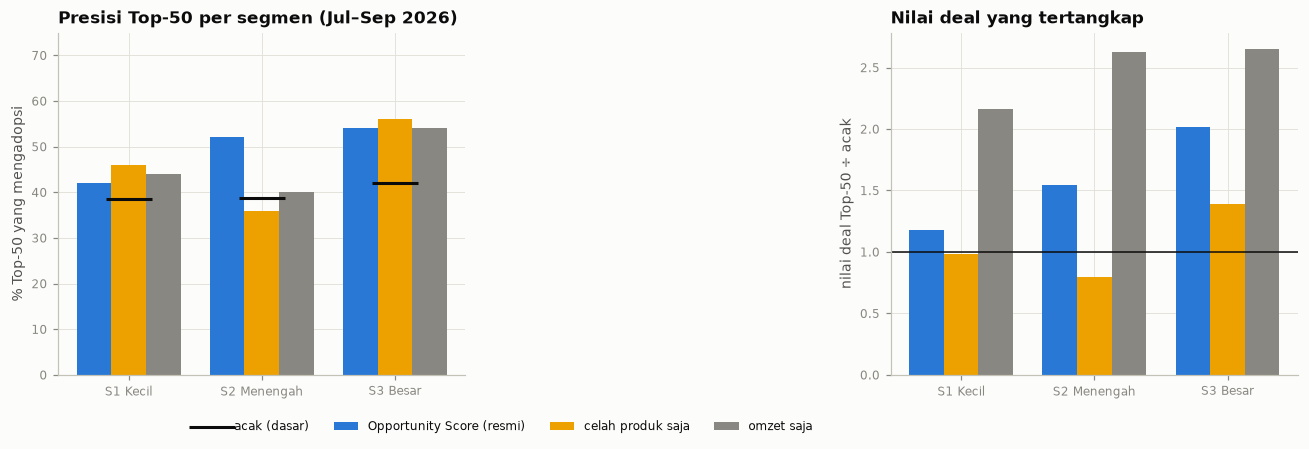

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
labs = ['Opportunity Score (resmi)', 'celah produk saja', 'omzet saja']; cols = [C['s1'], C['s4'], C['muted']]; w = .26; x = np.arange(len(SEGS))
for i, (l, c) in enumerate(zip(labs, cols)):
    d = VAL_CO[VAL_CO.ranking == l].set_index('segmen').loc[SEGS]
    ax[0].bar(x + (i - 1) * w, d.presisi_top * 100, w, color=c, label=l); ax[1].bar(x + (i - 1) * w, d.deal_lift, w, color=c, label=l)
base = VAL_CO[VAL_CO.ranking == labs[0]].set_index('segmen').loc[SEGS].adopsi_dasar * 100
ax[0].scatter(x, base, marker='_', s=900, color=C['ink'], label='acak (dasar)', zorder=5)
ax[0].set_xticks(x); ax[0].set_xticklabels(SEGS); ax[0].set_ylabel(f'% Top-{TOP_N} yang mengadopsi'); ax[0].set_title('Presisi Top-50 per segmen (Jul–Sep 2026)'); ax[0].set_ylim(0, 75)
ax[0].legend(loc='upper center', bbox_to_anchor=(1.1, -0.1), ncol=4)
ax[1].axhline(1, color=C['ink'], lw=1); ax[1].set_xticks(x); ax[1].set_xticklabels(SEGS); ax[1].set_ylabel('nilai deal Top-50 ÷ acak'); ax[1].set_title('Nilai deal yang tertangkap')
plt.tight_layout(); save_fig(fig, 'H_validation'); plt.show()

**Cara membaca (ditulis sebelum hasil dilihat tim):**
- **Lift > 1 terhadap acak** = skor berguna. Pembanding yang adil adalah **omzet saja**, karena itu yang dipakai RM tanpa model.
- Di **nilai deal**, ranking omzet secara alami unggul: perusahaan besar = deal besar. Opportunity Score sengaja menimbang retensi dan celah produk, bukan ukuran saja.
- Bila Opportunity Score **tidak** lebih baik dari omzet saja di suatu segmen, itu temuan, bukan kegagalan yang disembunyikan. Langkah lanjutnya:
  1. bobot dikalibrasi ulang dengan **data adopsi kuartal berikutnya**;
  2. log-omzet ditambahkan sebagai komponen "nilai" (diputuskan **sebelum** melihat kuartal berikutnya).

## I. Uji sensitivitas
1. **Bobot:** tiap bobot komponen di tiap segmen diubah ±20%, satu per satu. Ukurannya irisan Top-50 (Jaccard) dengan daftar resmi.
2. **Asumsi EV:** margin, biaya aksi, LGD, dan PD diubah ±20%; horizon 1 → 3 tahun. Ukurannya perubahan total EV Top-50 per segmen.
   EV tidak dipakai untuk ranking, jadi daftar Top-50 tidak berubah.

In [36]:
seg_s = seg.reindex(ids_s).values
base_top = {s: set(OPP[OPP.segment == s].nsmallest(TOP_N, 'rank_in_segment').index) for s in SEGS}
rows = []
for s in SEGS:
    for k_ in OP.COMPONENTS:
        for f in (0.8, 1.2):
            W = json.loads(json.dumps(OP.DEFAULT_WEIGHTS)); W[s][k_] *= f
            sc, _ = OP.opportunity_score(C_s, seg_s, weights=W, why_now_up=up_s.reindex(ids_s).values, bonus=WHY_NOW_BONUS)
            t = set(sc[seg_s == s].nlargest(TOP_N).index); rows.append(dict(segmen=s, komponen=k_, faktor=f, jaccard_top50=len(t & base_top[s]) / len(t | base_top[s])))
SENS_W = pd.DataFrame(rows); SENS_W.to_csv(OUT / 'I_sensitivity_weights.csv', index=False)
display(SENS_W.groupby('segmen').jaccard_top50.agg(['min', 'median']).round(3))

def total_ev_top(A):
    e, _ = ev_rows(PL, DEAL, A); t = PL.assign(e=e)
    t1 = t[t.rank_produk == 1].set_index('company_id').e
    return {s: t1.reindex(list(base_top[s])).sum() for s in SEGS}
base_ev = total_ev_top(ASSUMPTIONS); rows = []
for key in ['margin_kredit', 'margin_non_kredit', 'biaya_aksi_Rp_juta', 'LGD', 'PD', 'horizon_tahun']:
    for f in ((0.8, 1.2) if key != 'horizon_tahun' else (3.0,)):
        A = json.loads(json.dumps(ASSUMPTIONS))
        A[key] = {k: v * f for k, v in A[key].items()} if isinstance(A[key], dict) else A[key] * f
        ev = total_ev_top(A)
        for s in SEGS: rows.append(dict(asumsi=key, faktor=f, segmen=s, ev_top50=ev[s], perubahan=ev[s] / base_ev[s] - 1 if base_ev[s] else np.nan))
for s in SEGS: rows.append(dict(asumsi='(dasar)', faktor=1.0, segmen=s, ev_top50=base_ev[s], perubahan=0.0))
SENS_A = pd.DataFrame(rows); SENS_A.to_csv(OUT / 'I_sensitivity_assumptions.csv', index=False)
display(SENS_A.pivot_table(index=['asumsi', 'faktor'], columns='segmen', values='ev_top50').round(1))
print('Total EV Top-50 dalam Rp juta. Persentase perubahan tidak ditampilkan, karena EV dasar yang mendekati nol membuatnya menyesatkan; lihat CSV.')

,min,median
segmen,,
S1 Kecil,0.852,0.905
S2 Menengah,0.754,0.869
S3 Besar,0.852,0.905


segmen                     S1 Kecil  S2 Menengah  S3 Besar
asumsi             faktor                                 
(dasar)            1.0          8.2        -33.4     121.0
LGD                0.8          9.0        -32.2     123.8
                   1.2          7.5        -34.6     118.2
PD                 0.8          8.2        -33.4     121.0
                   1.2          8.2        -33.4     121.0
biaya_aksi_Rp_juta 0.8         13.2        -13.4     171.0
                   1.2          3.2        -53.4      71.0
horizon_tahun      3.0         74.7         99.9     863.0
margin_kredit      0.8          5.1        -38.4     107.0
                   1.2         11.3        -28.3     135.0
margin_non_kredit  0.8          3.9        -42.9      58.0
                   1.2         12.5        -23.9     184.0

Total EV Top-50 dalam Rp juta. Persentase perubahan tidak ditampilkan, karena EV dasar yang mendekati nol membuatnya menyesatkan; lihat CSV.


## J. Simpan, ringkasan, dan pemakaian di Streamlit

In [37]:
EVSEG = OPP[OPP.rank_in_segment <= TOP_N].groupby('segment').agg(ev_top50=('ev_idr_mn', 'sum'), ev_low=('ev_low', 'sum'), ev_high=('ev_high', 'sum'),
                                                                   roi_median=('roi', 'median'), p_convert_median=('p_convert', 'median'))
EVSEG.to_csv(OUT / 'G_ev_by_segment_top50.csv'); display(EVSEG.round(2))

OPP.reset_index(names='company_id').to_csv(SCORES / 'opportunity_scores.csv', index=False)
PL.drop(columns=['skor']).rename(columns={'celah': 'need_score'}).to_csv(SCORES / 'opportunity_products.csv', index=False)
PR_.reset_index(names='company_id').to_csv(SCORES / 'prospect_acquisition_scores.csv', index=False)
pd.DataFrame({'company_id': co.index, 'segment': seg.values, 'segment_confidence': seg_conf.round(3).values, 'split': split.values,
              'customer_type': co.customer_type.values}).to_csv(SCORES / 'segments.csv', index=False)
arows = [('margin_kredit', ASSUMPTIONS['margin_kredit']), ('margin_non_kredit', ASSUMPTIONS['margin_non_kredit']), ('LGD', ASSUMPTIONS['LGD']),
         ('horizon_tahun', ASSUMPTIONS['horizon_tahun'])]
arows += [(f'PD_{k}', v) for k, v in ASSUMPTIONS['PD'].items()] + [(f'biaya_aksi_{k}_Rp_juta', v) for k, v in ASSUMPTIONS['biaya_aksi_Rp_juta'].items()]
arows += [(f'ukuran_deal_{s}_{q}_Rp_juta', round(v, 1)) for (s, q), v in DEAL.items()]
arows += [('medium_credit_factor', MEDIUM_CREDIT_FACTOR), ('why_now_bonus', WHY_NOW_BONUS), ('why_now_bulan', WHY_NOW_MONTHS)]
pd.DataFrame(arows, columns=['asumsi', 'nilai']).to_csv(SCORES / 'assumptions_opportunity.csv', index=False)

joblib.dump(SEG, M08 / 'segmenter.joblib')
if NEED_MODEL is not None: joblib.dump(NEED_MODEL, M08 / 'need_model.joblib')
joblib.dump({'model': CONV_MODEL, 'columns': CONV_COLS, 'pakai_skor': bool(USE_SCORE_IN_CONV)}, M08 / 'conversion_model.joblib')
CFG = {'dibuat': pd.Timestamp.now().isoformat(timespec='seconds'), 'ref_skor': REF_SCORE, 'k': K_BEST, 'segmen': SEGS,
       'fitur_skala': OP.SCALE_FEATURES, 'fit_pada': 'train + unlabeled', 'bobot': OP.DEFAULT_WEIGHTS, 'metode_celah_produk': NEED_METHOD,
       'produk_kredit': CREDIT, 'produk_ditawarkan': CAND, 'nama_produk': {p: pname(p) for p in PRODUCTS},
       'why_now': {'naik': list(OP.WHY_NOW_UP), 'hati_hati': list(OP.WHY_NOW_CAUTION), 'bulan': WHY_NOW_MONTHS, 'bonus': WHY_NOW_BONUS, 'sumber': WHY_SRC},
       'penyesuaian_risiko': {'High': 'kredit ditunda', 'Medium': MEDIUM_CREDIT_FACTOR}, 'asumsi': ASSUMPTIONS, 'top_n': TOP_N}
OP.save_config(M08 / 'opportunity_config.json', CFG)

REG = pd.DataFrame([
    ('segmen', 'outputs/scores/segments.csv', '2.000 perusahaan, segmen + keyakinan'),
    ('skor peluang nasabah', 'outputs/scores/opportunity_scores.csv', 'ranking RM per segmen, alasan, produk disarankan, EV'),
    ('skor per produk', 'outputs/scores/opportunity_products.csv', 'nasabah × produk: need, P(konversi), EV + rentang'),
    ('skor akuisisi prospect', 'outputs/scores/prospect_acquisition_scores.csv', 'deskriptif, belum tervalidasi'),
    ('asumsi', 'outputs/scores/assumptions_opportunity.csv', 'margin, biaya, PD/LGD, ukuran deal'),
    ('model', 'models/08_segmentation/', 'segmenter.joblib, conversion_model.joblib, opportunity_config.json')], columns=['isi', 'berkas', 'keterangan'])
REG.to_csv(OUT / 'J_registry.csv', index=False); display(REG)

,ev_top50,ev_low,ev_high,roi_median,p_convert_median
segment,,,,,
S1 Kecil,8.19,-5.15,28.11,0.37,0.26
S2 Menengah,-33.36,-48.87,-11.15,-0.30,0.23
S3 Besar,121.03,20.01,365.99,0.39,0.37


,isi,berkas,keterangan
0,segmen,outputs/scores/segments.csv,"2.000 perusahaan, segmen + keyakinan"
1,skor peluang nasabah,outputs/scores/opportunity_scores.csv,"ranking RM per segmen, alasan, produk disarankan, EV"
2,skor per produk,outputs/scores/opportunity_products.csv,"nasabah × produk: need, P(konversi), EV + rentang"
3,skor akuisisi prospect,outputs/scores/prospect_acquisition_scores.csv,"deskriptif, belum tervalidasi"
4,asumsi,outputs/scores/assumptions_opportunity.csv,"margin, biaya, PD/LGD, ukuran deal"
5,model,models/08_segmentation/,"segmenter.joblib, conversion_model.joblib, opportunity_config.json"


In [38]:
vo = VAL_CO[VAL_CO.ranking == 'Opportunity Score (resmi)'].set_index('segmen'); vr = VAL_CO[VAL_CO.ranking == 'omzet saja'].set_index('segmen')
seg_line = '; '.join(f"{s} n={int(PROF.loc[s, 'n'])}, omzet median Rp {PROF.loc[s, 'median_omzet_Rp_M']:.1f} M, konversi RM {PROF.loc[s, 'konversi_aksi_RM']:.0%}" for s in SEGS)
val_line = '; '.join(f"{s} {vo.loc[s, 'presisi_top']:.0%} vs dasar {vo.loc[s, 'adopsi_dasar']:.0%} (lift {vo.loc[s, 'lift']:.2f}×; omzet saja {vr.loc[s, 'presisi_top']:.0%}), nilai deal {vo.loc[s, 'deal_lift']:.2f}× acak (omzet saja {vr.loc[s, 'deal_lift']:.2f}×)" for s in SEGS)
SUMMARY = f"""
**Segmentasi:** k = {K_BEST} (Jaccard minimum {KSEL.loc[K_BEST, 'jaccard_min']:.2f}, silhouette {KSEL.loc[K_BEST, 'silhouette']:.2f}, NMI ukuran {KSEL.loc[K_BEST, 'NMI_ukuran']:.2f}). {f'{agree:.0%} selaras dengan kolom ukuran bank. ' if K_BEST == 3 else ''}Cramér's V konversi RM: segmen {v_seg:.3f} vs kolom ukuran {v_ref:.3f}.
{seg_line}.
**Celah produk:** metode = {NEED_METHOD} (backtest Des 2025 → Jan–Jun 2026; AUC {NEED_SEL.loc[NEED_METHOD, 'AUC_produk']:.3f}).
**P(konversi):** skor dipakai = {USE_SCORE_IN_CONV} (log-loss CV {ll1:.4f} vs {ll0:.4f} tanpa skor).
**Validasi Jul–Sep 2026 (presisi Top-{TOP_N}):** {val_line}.
AUC tingkat produk: celah {VAL_PROD.loc['semua', 'AUC_celah']:.3f}, P(konversi) {VAL_PROD.loc['semua', 'AUC_p_konversi']:.3f}.
**Sensitivitas bobot ±20%:** Jaccard Top-50 minimum {SENS_W.jaccard_top50.min():.2f}, median {SENS_W.jaccard_top50.median():.2f}.
**EV Top-{TOP_N} (Rp juta, ilustratif):** {'; '.join(f"{s} {EVSEG.loc[s, 'ev_top50']:,.0f} ({EVSEG.loc[s, 'ev_low']:,.0f}–{EVSEG.loc[s, 'ev_high']:,.0f})" for s in SEGS)}.
*Prospect: skor akuisisi deskriptif (log RM tidak memuat konversi prospect).*
"""
display(Markdown(SUMMARY)); (OUT / 'SUMMARY.md').write_text(SUMMARY, encoding='utf-8')
print(f'total waktu jalan: {(time.time() - T0) / 60:.1f} menit')


**Segmentasi:** k = 3 (Jaccard minimum 0.95, silhouette 0.34, NMI ukuran 0.57). 85% selaras dengan kolom ukuran bank. Cramér's V konversi RM: segmen 0.114 vs kolom ukuran 0.113.
S1 Kecil n=796, omzet median Rp 8.3 M, konversi RM 13%; S2 Menengah n=863, omzet median Rp 34.7 M, konversi RM 15%; S3 Besar n=341, omzet median Rp 172.7 M, konversi RM 24%.
**Celah produk:** metode = peer rate (champion) (backtest Des 2025 → Jan–Jun 2026; AUC 0.605).
**P(konversi):** skor dipakai = True (log-loss CV 0.4275 vs 0.4306 tanpa skor).
**Validasi Jul–Sep 2026 (presisi Top-50):** S1 Kecil 42% vs dasar 38% (lift 1.09×; omzet saja 44%), nilai deal 1.18× acak (omzet saja 2.17×); S2 Menengah 52% vs dasar 39% (lift 1.34×; omzet saja 40%), nilai deal 1.54× acak (omzet saja 2.62×); S3 Besar 54% vs dasar 42% (lift 1.29×; omzet saja 54%), nilai deal 2.02× acak (omzet saja 2.65×).
AUC tingkat produk: celah 0.576, P(konversi) 0.583.
**Sensitivitas bobot ±20%:** Jaccard Top-50 minimum 0.75, median 0.89.
**EV Top-50 (Rp juta, ilustratif):** S1 Kecil 8 (-5–28); S2 Menengah -33 (-49–-11); S3 Besar 121 (20–366).
*Prospect: skor akuisisi deskriptif (log RM tidak memuat konversi prospect).*


total waktu jalan: 0.5 menit


### Pemakaian di Streamlit
```python
sys.path.insert(0, str(PROJECT_ROOT / 'src')); import opportunity as OP
opp  = pd.read_csv(PROJECT_ROOT / 'outputs/scores/opportunity_scores.csv')        # halaman RM: filter segmen → urut rank_in_segment
prod = pd.read_csv(PROJECT_ROOT / 'outputs/scores/opportunity_products.csv')      # detail produk + EV (rentang)
cfg  = OP.load_config(PROJECT_ROOT / 'models/08_segmentation/opportunity_config.json')
seg  = joblib.load(PROJECT_ROOT / 'models/08_segmentation/segmenter.joblib')        # what-if: seg.names(seg.predict(X_baru))
```
Ranking RM **selalu per segmen**. EV ditampilkan sebagai rentang dan tidak dipakai untuk mengurutkan perusahaan lintas segmen.

## Daftar pustaka
- Hennig, C. (2007). Cluster-wise assessment of cluster stability. *Computational Statistics & Data Analysis*, 52(1), 258–271.
- Rousseeuw, P. J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. *J. Comput. Appl. Math.*, 20, 53–65.
- Davies, D. L. & Bouldin, D. W. (1979). A cluster separation measure. *IEEE TPAMI*, 1(2), 224–227.
- Hubert, L. & Arabie, P. (1985). Comparing partitions. *Journal of Classification*, 2, 193–218.
- Vinh, N. X., Epps, J. & Bailey, J. (2010). Information theoretic measures for clusterings comparison. *JMLR*, 11, 2837–2854.
- Cramér, H. (1946). *Mathematical Methods of Statistics*. Princeton University Press.
- Knott, A., Hayes, A. & Neslin, S. A. (2002). Next-product-to-buy models for cross-selling applications. *Journal of Interactive Marketing*, 16(3), 59–75.
- BCBS (2017). *Basel III: Finalising post-crisis reforms* (LGD F-IRB). Bank for International Settlements.